# Stage 1 — Inspecting the Limit Texas Hold'em environment

**Goal of this notebook:** before writing any neural network, confirm that we understand the
interface the learning agent will talk to. Everything downstream (state encoding, action masking,
reward scaling, PPO rollouts) depends on the facts verified here.

We use [RLCard](https://github.com/datamllab/rlcard)'s `limit-holdem` environment:

* heads-up (2 players), fixed-limit betting, blinds 1/2 chips;
* 4 actions — `call`, `raise`, `fold`, `check`;
* reward = chips won, **normalised by the big blind**, so `+1.0` means "won one big blind".

This notebook checks, in order: versions, environment setup, one complete random hand,
observation structure, information leakage, a readable action log, and behaviour over many hands.

## 1. Dependency and version checks

If the interpreter printed below is not `poker-ai-arena\.venv\Scripts\python.exe`, the kernel is
wrong — select the `.venv` interpreter in VS Code before running anything else.

In [1]:
import sys

import matplotlib
import numpy as np
import pytest
import rlcard
import torch

print(f"Python      : {sys.version.split()[0]}")
print(f"Interpreter : {sys.executable}")
print(f"rlcard      : {rlcard.__version__}")
print(f"torch       : {torch.__version__}")
print(f"numpy       : {np.__version__}")
print(f"matplotlib  : {matplotlib.__version__}")
print(f"pytest      : {pytest.__version__}")

if ".venv" not in sys.executable.lower():
    print("\nWARNING: this kernel is not the project .venv")
else:
    print("\nKernel is the project .venv")

Python      : 3.14.6
Interpreter : C:\Users\laksh\OneDrive\Documents\Default Project\poker-ai-arena\.venv\Scripts\python.exe
rlcard      : 1.2.0
torch       : 2.15.0+cpu
numpy       : 2.5.4
matplotlib  : 3.11.2
pytest      : 9.2.0

Kernel is the project .venv


## 2. Initialising the environment

`rlcard.make` returns an `Env` wrapper. Three things are worth pointing out:

* `config={"seed": ...}` seeds the **card dealer only**. It does not make `RandomAgent`
  deterministic, because `RandomAgent` draws from NumPy's global RNG (we seed that separately
  with `np.random.seed`).
* `allow_step_back=False` is the default. Replaying/undoing hands is only needed for search
  algorithms like CFR, not for PPO.
* `state_shape` tells us the observation is a flat vector of length 72.

In [2]:
SEED = 42

env = rlcard.make("limit-holdem", config={"seed": SEED})

print(f"players           : {env.num_players}")
print(f"actions           : {env.num_actions}")
print(f"action names      : {env.actions}")
print(f"state_shape       : {env.state_shape}")
print(f"action_shape      : {env.action_shape}")
print(f"allow_step_back   : {env.allow_step_back}")

players           : 2
actions           : 4
action names      : ['call', 'raise', 'fold', 'check']
state_shape       : [[72], [72]]
action_shape      : [None, None]
allow_step_back   : False


### Action IDs

`env.actions` is the authoritative mapping. Note the order: `check` is **ID 3**, not ID 2.
Hard-coding these numbers anywhere else in the project would be a bug, so we always read the
mapping from the environment.

| ID | Name |
|----|------|
| 0 | `call` |
| 1 | `raise` |
| 2 | `fold` |
| 3 | `check` |

`state["legal_actions"]` lists the legal action **IDs for the current state** and changes every
turn; `env.actions` is the fixed global vocabulary.

## 3. One complete hand with random agents

`env.run(is_training=False)` plays one hand from deal to showdown. It expects `env.set_agents`
to have been called first and returns a tuple `(trajectories, payoffs)`:

* `trajectories` — per-player list of `(obs, action, obs, ...)`, used later as rollout data;
* `payoffs` — one float per player, in big blinds.

We seed NumPy immediately before `run` so the random agents' choices are reproducible.

In [3]:
from rlcard.agents import RandomAgent

np.random.seed(SEED)
env.set_agents([RandomAgent(env.num_actions) for _ in range(env.num_players)])

trajectories, payoffs = env.run(is_training=False)

print(f"hand finished   : {env.is_over()}")
print(f"payoffs         : {payoffs}")
print(f"payoff sum      : {np.sum(payoffs):.1f}")
print(f"traj len (P0,P1): {[len(t) for t in trajectories]}")

assert env.is_over(), "hand did not terminate"
assert abs(np.sum(payoffs)) < 1e-9, "limit hold'em must be zero-sum"

hand finished   : True
payoffs         : [-0.5  0.5]
payoff sum      : 0.0
traj len (P0,P1): [3, 1]


The hand terminated and paid out exactly zero sum. Payoff values are multiples of `0.5` because
the big blind is 2 chips and everything is divided by it — a player who folds the small blind
loses 1 chip = `-0.5`.

`traj len` counts entries per player; each transition stores `obs`, `action`, `obs`, so the count
is *not* the number of decisions. We will build our own rollout buffer in a later stage.

## 4. What does the observation actually contain?

The extracted state is a `dict`. The one-hot vector `obs` is what a neural network would consume;
`raw_obs` is the readable version of the same information.

In [4]:
state, current_player = env.reset()

print(f"starting player : {current_player}")
print(f"state keys      : {list(state.keys())}")
print(f"obs shape/dtype : {state['obs'].shape} {state['obs'].dtype}")
print(f"obs is one-hot  : {np.unique(state['obs'])}")
print(f"legal action ids: {list(state['legal_actions'].keys())}")
print(f"legal names     : {state['raw_legal_actions']}")
print(f"raw_obs         : {state['raw_obs']}")

starting player : 0
state keys      : ['legal_actions', 'obs', 'raw_obs', 'raw_legal_actions', 'action_record']
obs shape/dtype : (72,) float64
obs is one-hot  : [0. 1.]
legal action ids: [0, 1, 2]
legal names     : ['call', 'raise', 'fold']
raw_obs         : {'hand': ['HQ', 'SJ'], 'public_cards': [], 'all_chips': [1, 2], 'my_chips': 1, 'legal_actions': ['call', 'raise', 'fold'], 'raise_nums': [0, 0, 0, 0]}


### Decoding the 72-dimensional vector

The layout is fixed by `LimitholdemEnv._extract_state`:

| Slice | Meaning |
|-------|---------|
| `obs[0:52]` | one-hot over the 52-card deck: the acting player's **hole cards + public cards** |
| `obs[52:72]` | 4 betting rounds x 5 slots; slot `n` is set when that round saw `n` raises |

The 52-card ordering comes from RLCard's `card2index.json`, which the env exposes as
`env.card2index`. We invert it here to turn indices back into readable cards.

In [5]:
index_to_card = {idx: card for card, idx in env.card2index.items()}


def decode_obs(obs):
    """Turn a 72-dim observation into readable cards and per-round raise counts."""
    cards = [index_to_card[i] for i in np.flatnonzero(obs[:52])]
    raise_blocks = obs[52:].reshape(4, 5)
    raises_per_round = [int(np.argmax(block)) if block.any() else 0 for block in raise_blocks]
    return {"cards": cards, "raises_per_round": raises_per_round}


decoded = decode_obs(state["obs"])
print(f"cards in observation : {decoded['cards']}   (ordered by card index)")
print(f"cards in raw_obs     : {state['raw_obs']['hand'] + state['raw_obs']['public_cards']}   (dealt order)")
print(f"same card set        : {set(decoded['cards']) == set(state['raw_obs']['hand'])}")
print(f"raises per round     : {decoded['raises_per_round']}")

cards in observation : ['SJ', 'HQ']   (ordered by card index)
cards in raw_obs     : ['HQ', 'SJ']   (dealt order)
same card set        : True
raises per round     : [0, 0, 0, 0]


The observation contains **exactly 2 cards preflop**: the acting player's own hole cards.
Public cards will appear in this same slice as they are dealt, but at no point does the acting
player's observation contain the opponent's hole cards.

### Leakage check

A stronger test than eyeballing: build both players' observations for the *same* game state and
compare them. Any position where they differ must be a hole-card slot (index `< 52`). If public
information differed, or if one vector contained the other player's private cards, the difference
would show up elsewhere.

In [6]:
obs_p0 = env.get_state(0)["obs"]
obs_p1 = env.get_state(1)["obs"]

differing = np.flatnonzero(obs_p0 != obs_p1)
print(f"positions that differ : {differing.tolist()}")
print(f"all inside hand region: {bool((differing < 52).all())}")

assert (differing < 52).all(), "public information differs between players"

print("\nWARNING: env.get_perfect_information() DOES expose both hands.")
print("It is for debugging only - never feed it to a policy.")
print(f"perfect info hand cards: {env.get_perfect_information()['hand_cards']}")

positions that differ : [6, 10, 24, 42]
all inside hand region: True

It is for debugging only - never feed it to a policy.
perfect info hand cards: [['HQ', 'SJ'], ['S7', 'C4']]


## 5. A readable record of one hand

To *see* the hand play out we step manually instead of calling `run`. After every `env.step`
we record the acting player, the action name, the street, the board, and the pot.

Note the two-step decoding: `state["legal_actions"]` gives action **IDs**, while
`state["raw_legal_actions"]` gives the matching **names** in the same order.

In [7]:
# RLCard deals 0, 3, 4 then 5 public cards - there is no 1- or 2-card street.
STREETS = {0: "preflop", 3: "flop", 4: "turn", 5: "river"}

DEMO_SEED = 25  # chosen because this seed plays all four streets and reaches showdown
demo_env = rlcard.make("limit-holdem", config={"seed": DEMO_SEED})
rng = np.random.default_rng(DEMO_SEED)  # local RNG so this cell is reproducible
state, player_id = demo_env.reset()

print(f"{'street':<9}{'player':<8}{'action':<8}{'pot':>4}  board")
print("-" * 62)

while not demo_env.is_over():
    raw = state["raw_obs"]
    board = " ".join(raw["public_cards"]) or "-"
    pot = sum(raw["all_chips"])

    legal_ids = list(state["legal_actions"].keys())
    action_id = int(rng.choice(legal_ids))
    # legal_actions and raw_legal_actions are parallel lists
    action_name = state["raw_legal_actions"][legal_ids.index(action_id)]
    print(f"{STREETS[len(raw['public_cards'])]:<9}P{player_id:<7}{action_name:<8}{pot:>4}  {board}")

    state, player_id = demo_env.step(action_id)

print("-" * 62)
print(f"final payoffs : {demo_env.get_payoffs()}")

street   player  action   pot  board
--------------------------------------------------------------
preflop  P0      raise      3  -
preflop  P1      call       6  -
flop     P0      check      8  CT S2 S3
flop     P1      raise      8  CT S2 S3
flop     P0      call      10  CT S2 S3
turn     P1      raise     12  CT S2 S3 DQ
turn     P0      raise     16  CT S2 S3 DQ
turn     P1      raise     24  CT S2 S3 DQ
turn     P0      call      32  CT S2 S3 DQ
river    P1      raise     36  CT S2 S3 DQ C9
river    P0      raise     40  CT S2 S3 DQ C9
river    P1      call      48  CT S2 S3 DQ C9
--------------------------------------------------------------
final payoffs : [-13.  13.]


### The action recorder

`env.action_recorder` keeps every action as `(player_id, action_name)` and is cleared on
`reset()`. The API documents it for the human interface, but it is also the cheapest source of
betting history — which is exactly what the Stage 3/4 GRU agent will want.

In [8]:
print(f"actions this hand ({len(demo_env.action_recorder)}):")
for i, (pid, action) in enumerate(demo_env.action_recorder):
    print(f"  {i:>2}. P{pid} {action}")

actions this hand (12):
   0. P0 raise
   1. P1 call
   2. P0 check
   3. P1 raise
   4. P0 call
   5. P1 raise
   6. P0 raise
   7. P1 raise
   8. P0 call
   9. P1 raise
  10. P0 raise
  11. P1 call


## 6. Two behaviours to be careful about

Both of these were verified against RLCard 1.2.0 rather than assumed.

**(a) `action_record` is a live list, not a copy.** Every state returned by `reset`/`step`
references the *same* `env.action_recorder`. If you store states in a rollout buffer, they all
retroactively show the history of the whole hand.

**(b) Illegal actions are silently substituted.** `env.step` never raises on an illegal action ID;
`_decode_action` quietly replaces it with `check` if legal, otherwise `fold`.

In [9]:
alias_env = rlcard.make("limit-holdem", config={"seed": 11})
state, _ = alias_env.reset()
snapshot = state["action_record"]

print(f"len(snapshot) before step : {len(snapshot)}")
alias_env.step(0)
print(f"len(snapshot) after step  : {len(snapshot)}  <- grew without touching snapshot")

len(snapshot) before step : 0
len(snapshot) after step  : 1  <- grew without touching snapshot


In [10]:
ill_env = rlcard.make("limit-holdem", config={"seed": 11})
state, _ = ill_env.reset()

print(f"legal now        : {state['raw_legal_actions']}")
print(f"we send ID 3     : 'check'")
ill_env.step(3)
print(f"env recorded     : {ill_env.action_recorder[-1][1]!r}")
print("\n-> the env substituted a legal action; a bad action mask would silently")
print("   train the network on actions it never chose.")

legal now        : ['call', 'raise', 'fold']
we send ID 3     : 'check'
env recorded     : 'fold'

-> the env substituted a legal action; a bad action mask would silently
   train the network on actions it never chose.


**Consequences for the project:** always pass a *masked* action distribution to the policy, and
always copy the history (`list(state["action_record"])`) if it is stored.

## 7. Many hands in a row

`reset()` starts a fresh hand on the same `Env` object — no re-creation needed. We run 500 hands
to confirm the environment is stable across resets and to look at payoff variance.

Note: `env.timestep` is a cumulative counter that is *not* cleared by `reset()`, so it should not
be used as a per-hand counter.

In [11]:
N_HANDS = 500

np.random.seed(SEED)  # RandomAgent uses the global RNG
env.set_agents([RandomAgent(env.num_actions) for _ in range(env.num_players)])

all_payoffs = np.array([env.run(is_training=False)[1] for _ in range(N_HANDS)], dtype=float)

print(f"hands simulated     : {N_HANDS}")
print(f"payoff array shape  : {all_payoffs.shape}")
print(f"zero-sum max error  : {np.abs(all_payoffs.sum(axis=1)).max():.2e}")
print(f"P0 mean / std       : {all_payoffs[:, 0].mean():+.3f} / {all_payoffs[:, 0].std():.3f}")
print(f"P0 win / lose / tie : {(all_payoffs[:, 0] > 0).mean():.1%} / "
      f"{(all_payoffs[:, 0] < 0).mean():.1%} / {(all_payoffs[:, 0] == 0).mean():.1%}")

assert (np.abs(all_payoffs.sum(axis=1)) < 1e-9).all(), "a hand was not zero-sum"

hands simulated     : 500


payoff array shape  : (500, 2)


zero-sum max error  : 0.00e+00
P0 mean / std       : +0.027 / 2.268
P0 win / lose / tie : 51.0% / 49.0% / 0.0%


## 8. Payoff distribution

With two equally random agents the expected value is ~0. The spread is what matters: it is
roughly ±2 big blinds per hand, so any later "improvement" must be judged over hundreds of hands,
not a handful. This motivates the evaluation harness in the next stage.

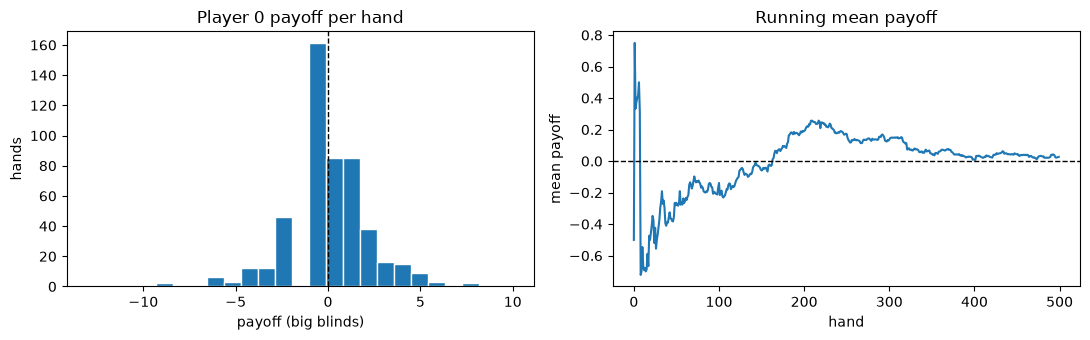

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

axes[0].hist(all_payoffs[:, 0], bins=25, edgecolor="white")
axes[0].axvline(0, color="black", linewidth=1, linestyle="--")
axes[0].set_title("Player 0 payoff per hand")
axes[0].set_xlabel("payoff (big blinds)")
axes[0].set_ylabel("hands")

running_mean = np.cumsum(all_payoffs[:, 0]) / np.arange(1, N_HANDS + 1)
axes[1].plot(running_mean)
axes[1].axhline(0, color="black", linewidth=1, linestyle="--")
axes[1].set_title("Running mean payoff")
axes[1].set_xlabel("hand")
axes[1].set_ylabel("mean payoff")

fig.tight_layout()
plt.show()

### Is 500 hands enough to claim one agent is better?

No. The standard error of the mean here is `std / sqrt(N)`. We compute it explicitly so the next
stage can size its evaluation runs instead of eyeballing a plot.

In [13]:
p0 = all_payoffs[:, 0]
standard_error = p0.std(ddof=1) / np.sqrt(len(p0))
ci95 = 1.96 * standard_error

# n needed so that the 95% CI half-width shrinks to a given edge size
edge = 0.05
hands_for_edge = int(np.ceil((1.96 * p0.std(ddof=1) / edge) ** 2))

print(f"mean +/- 95% CI : {p0.mean():+.3f} +/- {ci95:.3f} big blinds")
print(f"hands needed to resolve a {edge} bb edge at 95% CI: ~{hands_for_edge:,}")

mean +/- 95% CI : +0.027 +/- 0.199 big blinds
hands needed to resolve a 0.05 bb edge at 95% CI: ~7,920


## 9. Summary

**Verified against RLCard 1.2.0 / Python 3.14.6**

| Fact | Value |
|---|---|
| Environment | `limit-holdem`, 2 players, 4 actions |
| Action IDs | `0 call`, `1 raise`, `2 fold`, `3 check` |
| Observation | `dict` with `obs` (72-dim float one-hot), `raw_obs`, `legal_actions`, `raw_legal_actions`, `action_record` |
| `obs` layout | `[0:52]` own hole cards + public cards, `[52:72]` raises per round |
| Reward | chips / big blind, zero-sum, multiples of 0.5 |
| API | `reset() -> (state, player_id)`, `step(id) -> (state, player_id)`, `run() -> (trajectories, payoffs)` |
| Hand replay | `env.action_recorder`, list of `(player_id, action_name)` |

**Confirmed risks**

1. `state["action_record"]` is a shared live list — copy it before storing.
2. Illegal action IDs are silently replaced — action masking is our responsibility.
3. `config["seed"]` seeds the dealer only; `RandomAgent` needs `np.random.seed`.
4. `env.timestep` accumulates across hands.
5. `get_perfect_information()` exposes both hands — debug only.

**Still unknown / next stage**

* How much of the 72-dim vector is actually useful signal? (Most of it is a sparse card encoding.)
* The observation has **no explicit memory** of who bet what earlier — only raise counts.
  This is precisely the gap the GRU agent (Agent B) is meant to close.
* Baseline strength is unmeasured: we need fixed rule-based opponents before PPO numbers mean
  anything.
* 500 hands is far too few to detect a real edge; an evaluation harness with confidence
  intervals is required first.